In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("../diabetes_binary_classification_data.csv")

target = "Diabetes_binary"

print(df.shape)
print(df.columns.tolist())

(253680, 22)
['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [5]:
# Numerical features
numerical_features = [
    "BMI",
    "MentHlth",
    "PhysHlth"
]

# Binary categorical features
binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]

# Ordered categorical features
ordered_features = [
    "GenHlth",
    "Age",
    "Education",
    "Income"
]

### Numerical features

The numerical features are compared between class 0 and class 1 using descriptive statistics and histograms. This allows us to examine whether the distributions differ between people without diabetes and people with diabetes. Differences in the centre, spread, or shape of the distributions may indicate that a feature is associated with `Diabetes_binary`.


--- BMI ---
                      mean  median       std
Diabetes_binary                             
0.0              27.805770    27.0  6.291414
1.0              31.944011    31.0  7.363401


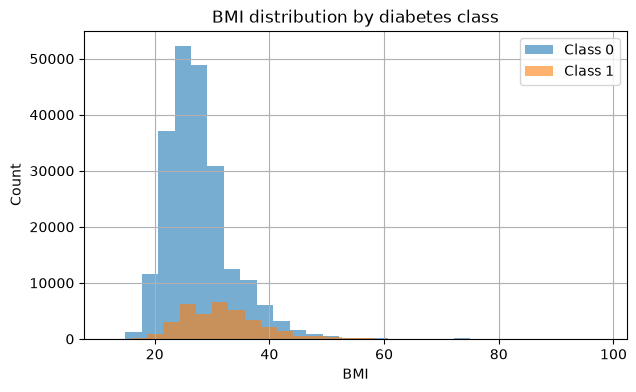


--- MentHlth ---
                     mean  median       std
Diabetes_binary                            
0.0              2.978034     0.0  7.111865
1.0              4.461806     0.0  8.947717


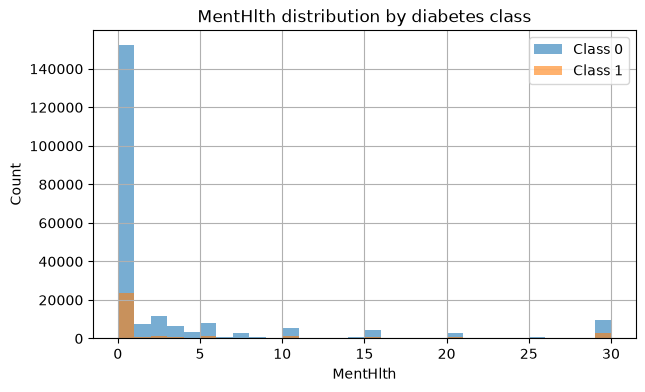


--- PhysHlth ---
                     mean  median        std
Diabetes_binary                             
0.0              3.641082     0.0   8.064600
1.0              7.954479     1.0  11.301491


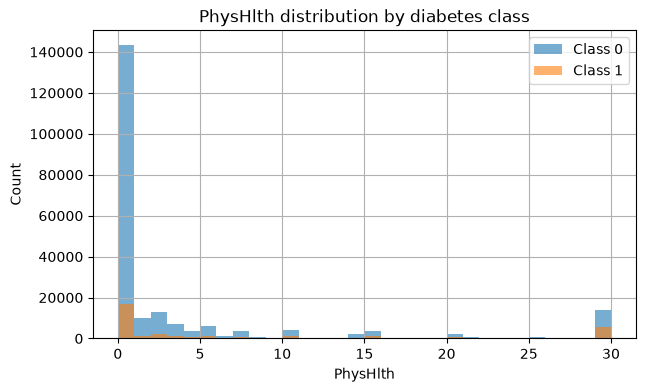

In [6]:
for feature in numerical_features:
    print(f"\n--- {feature} ---")
    
    print(
        df.groupby(target)[feature]
        .agg(["mean", "median", "std"])
    )

    plt.figure(figsize=(7, 4))

    df[df[target] == 0][feature].hist(
        bins=30,
        alpha=0.6,
        label="Class 0"
    )

    df[df[target] == 1][feature].hist(
        bins=30,
        alpha=0.6,
        label="Class 1"
    )

    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.title(f"{feature} distribution by diabetes class")
    plt.legend()
    plt.show()

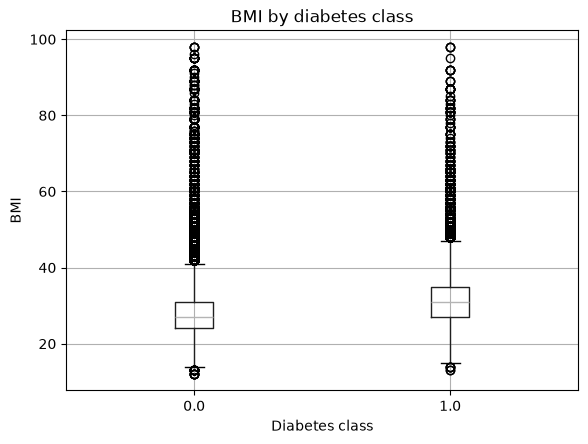

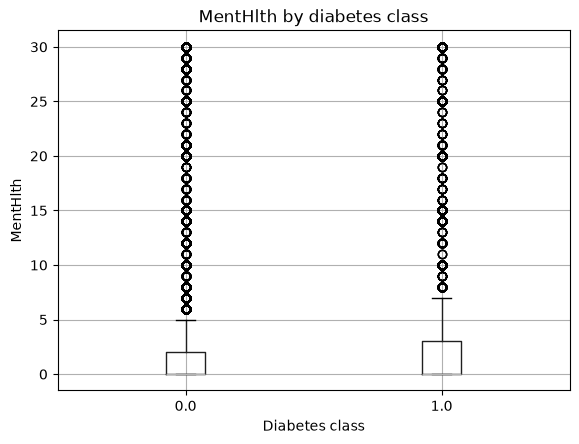

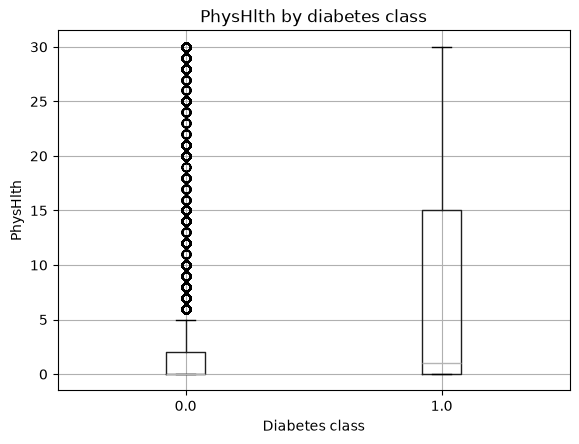

In [7]:
for feature in numerical_features:
    df.boxplot(column=feature, by=target)

    plt.xlabel("Diabetes class")
    plt.ylabel(feature)
    plt.title(f"{feature} by diabetes class")
    plt.suptitle("")
    plt.show()

The boxplots give another view of the numerical features by comparing their median, spread, and possible outliers between the two diabetes classes. This makes it easier to identify differences that may not be as clear from the histograms alone.


--- HighBP ---
         Count  Diabetes_proportion
HighBP                             
0.0     144851             0.060352
1.0     108829             0.244457


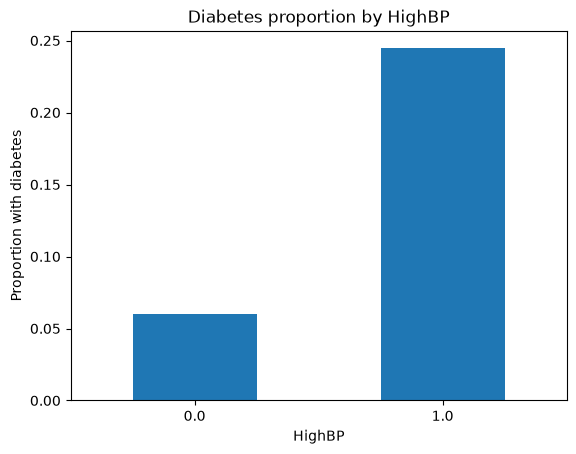


--- HighChol ---
           Count  Diabetes_proportion
HighChol                             
0.0       146089             0.079814
1.0       107591             0.220149


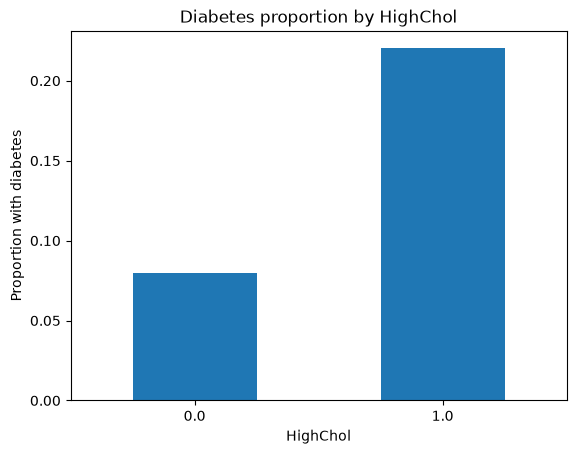


--- CholCheck ---
            Count  Diabetes_proportion
CholCheck                             
0.0          9470             0.025449
1.0        244210             0.143749


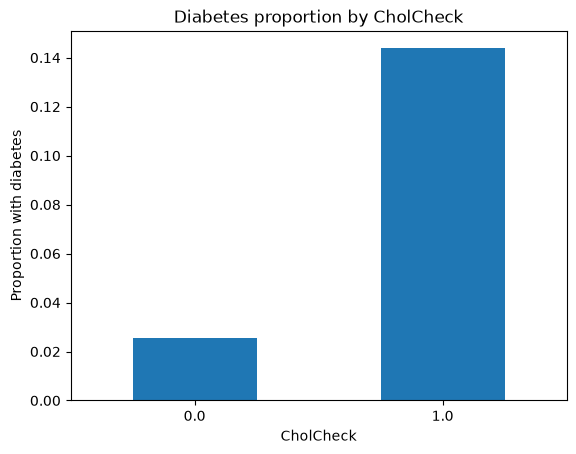


--- Smoker ---
         Count  Diabetes_proportion
Smoker                             
0.0     141257             0.120553
1.0     112423             0.162929


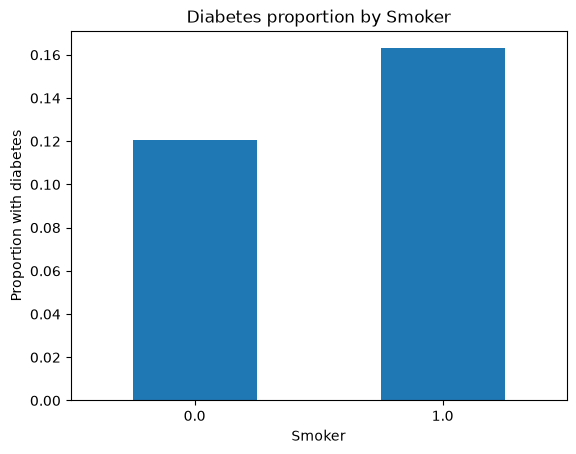


--- Stroke ---
         Count  Diabetes_proportion
Stroke                             
0.0     243388             0.131798
1.0      10292             0.317528


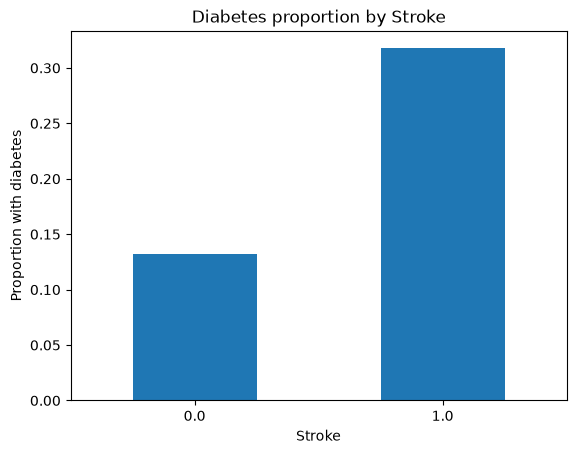


--- HeartDiseaseorAttack ---
                       Count  Diabetes_proportion
HeartDiseaseorAttack                             
0.0                   229787             0.119537
1.0                    23893             0.329720


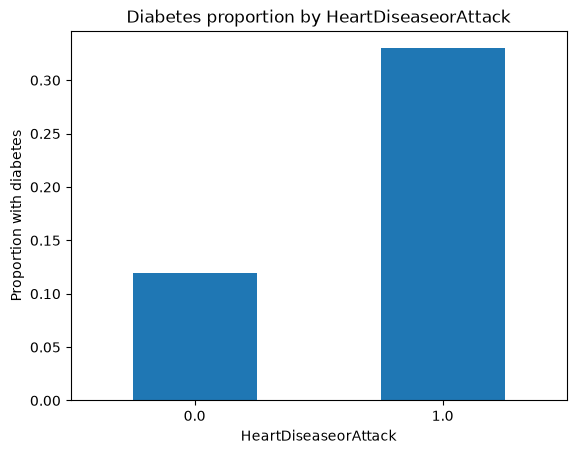


--- PhysActivity ---
               Count  Diabetes_proportion
PhysActivity                             
0.0            61760             0.211448
1.0           191920             0.116127


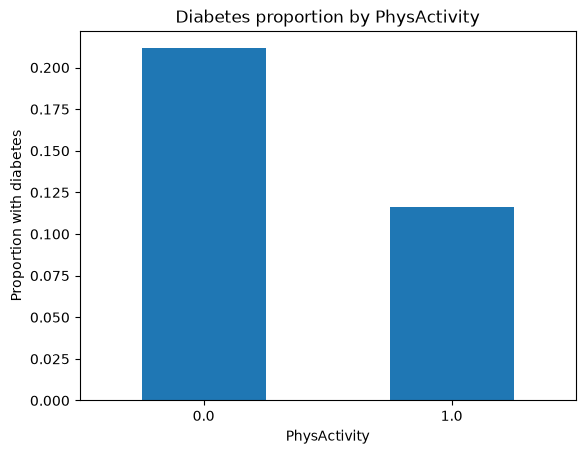


--- Fruits ---
         Count  Diabetes_proportion
Fruits                             
0.0      92782             0.157929
1.0     160898             0.128609


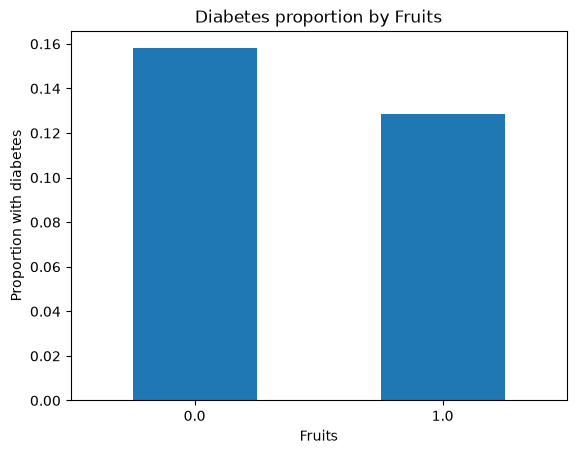


--- Veggies ---
          Count  Diabetes_proportion
Veggies                             
0.0       47839             0.179979
1.0      205841             0.129887


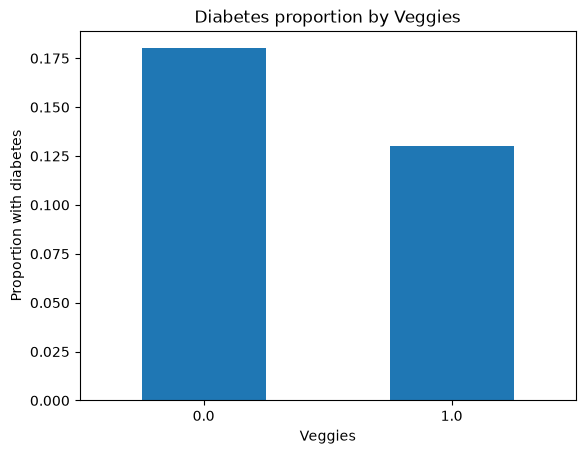


--- HvyAlcoholConsump ---
                    Count  Diabetes_proportion
HvyAlcoholConsump                             
0.0                239424             0.144154
1.0                 14256             0.058361


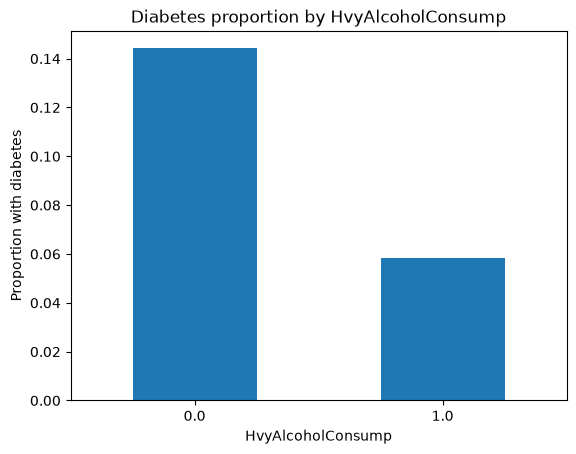


--- AnyHealthcare ---
                Count  Diabetes_proportion
AnyHealthcare                             
0.0             12417              0.11452
1.0            241263              0.14061


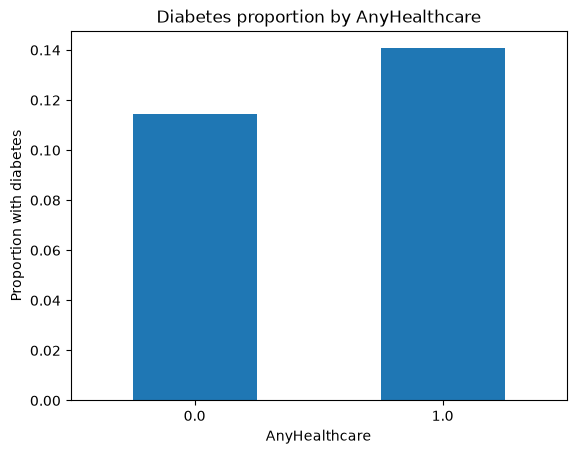


--- NoDocbcCost ---
              Count  Diabetes_proportion
NoDocbcCost                             
0.0          232326             0.136033
1.0           21354             0.175236


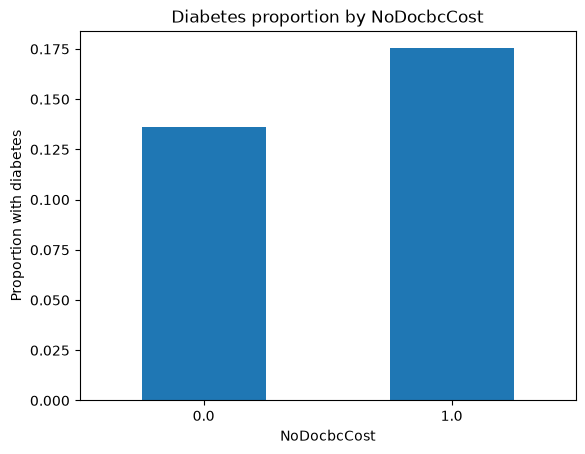


--- DiffWalk ---
           Count  Diabetes_proportion
DiffWalk                             
0.0       211005             0.105329
1.0        42675             0.307463


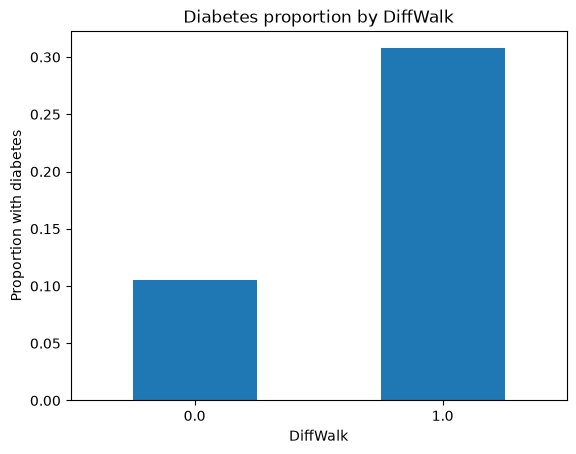


--- Sex ---
      Count  Diabetes_proportion
Sex                             
0.0  141974             0.129679
1.0  111706             0.151603


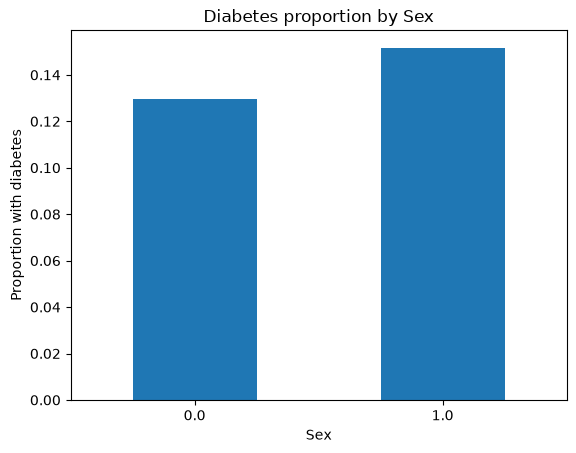

In [8]:
for feature in binary_features:
    print(f"\n--- {feature} ---")

    result = df.groupby(feature)[target].agg(
        Count="count",
        Diabetes_proportion="mean"
    )

    print(result)

    result["Diabetes_proportion"].plot(kind="bar")

    plt.xlabel(feature)
    plt.ylabel("Proportion with diabetes")
    plt.title(f"Diabetes proportion by {feature}")
    plt.xticks(rotation=0)
    plt.show()

### Binary categorical features

For the binary categorical features, the proportion of observations belonging to class 1 is compared between the two categories. This helps show whether the proportion of diabetes differs depending on whether the feature has a value of 0 or 1.

In [9]:
summary = []

for feature in numerical_features:
    class_0_mean = df[df[target] == 0][feature].mean()
    class_1_mean = df[df[target] == 1][feature].mean()

    summary.append({
        "Feature": feature,
        "Type": "Numerical",
        "Class 0 mean": class_0_mean,
        "Class 1 mean": class_1_mean
    })

numerical_summary = pd.DataFrame(summary)
numerical_summary

,Feature,Type,Class 0 mean,Class 1 mean
0,BMI,Numerical,27.805770,31.944011
1,MentHlth,Numerical,2.978034,4.461806
2,PhysHlth,Numerical,3.641082,7.954479


### Ordered categorical features

For the ordered categorical features, the proportion of class 1 is examined across the ordered categories. This allows us to see whether the proportion of diabetes tends to increase, decrease, or remain relatively stable as the category changes.

### Step 2 summary

The exploratory analysis shows how the different input features are associated with `Diabetes_binary`. Some features may show clearer differences between the two classes than others. The most informative results will be discussed in more detail, while features with little visible relationship to the target are still included in the overall exploration.

These results describe associations in the observed dataset and should not be interpreted as evidence that any feature causes diabetes.